## 1.. How to read csv data or how to load data  ! 

In [1]:
### lets import all the necessary packages !

In [2]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [5]:
comments = pd.read_csv(
   r"C:\Data Analytics project\project- 1 youtube case-study\UScomments.csv",
    on_bad_lines='skip'
)

In [6]:
### above is a warning , u can ignore that ..

In [7]:
 comments.head()

,video_id,comment_text,likes,replies
0,XpVt6Z1Gjjo,Logan Paul it's yo big day ‼️‼️‼️,4,0
1,XpVt6Z1Gjjo,I've been following you from the start of your...,3,0
2,XpVt6Z1Gjjo,Say hi to Kong and maverick for me,3,0
3,XpVt6Z1Gjjo,MY FAN . attendance,3,0
4,XpVt6Z1Gjjo,trending 😉,3,0


In [8]:
## lets find out missing values in your data
comments.isnull().sum()

video_id        0
comment_text    0
likes           0
replies         0
dtype: int64

In [9]:
## drop missing values as we have very few & lets update dataframe as well..
comments.dropna(inplace=True)

In [10]:
comments.isnull().sum()

video_id        0
comment_text    0
likes           0
replies         0
dtype: int64

## 2.. Perform Sentiment Analysis
    
    In short , Sentiment analysis is all about analyszing sentiments of Users

In [11]:
!pip install -q textblob
### lets perform sentiment analysis using TextBlob which is a NLP library built on top of NLTK )..


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
## if you are getting error in textblob while installing using pip ..
## you can install textblob using conda in Anazonda prompt 

## conda install -c conda-forge textblob  

In [13]:
from textblob import TextBlob

In [14]:
comments.head(6)

,video_id,comment_text,likes,replies
0,XpVt6Z1Gjjo,Logan Paul it's yo big day ‼️‼️‼️,4,0
1,XpVt6Z1Gjjo,I've been following you from the start of your...,3,0
2,XpVt6Z1Gjjo,Say hi to Kong and maverick for me,3,0
3,XpVt6Z1Gjjo,MY FAN . attendance,3,0
4,XpVt6Z1Gjjo,trending 😉,3,0
5,XpVt6Z1Gjjo,#1 on trending AYYEEEEE,3,0


In [15]:
TextBlob("Logan Paul it's yo big day ‼️‼️‼️").sentiment.polarity

### its a neutral sentence !

0.0

In [16]:
comments.shape

(1000, 4)

In [17]:
## for those of you who dont have good specifications , considering sample of data is a good option !

sample_df = comments[0:1000]

In [18]:
sample_df.shape

(1000, 4)

In [20]:
polarity = []

for comment in comments['comment_text']:
    try:
        polarity.append(TextBlob(comment).sentiment.polarity)
    except:
        polarity.append(0)

In [21]:
len(polarity)

1000

In [22]:
comments['polarity']  = polarity

### Inserting polarity values into comments dataframe while defining feature name as "polarity"

In [23]:
comments.head(5)

,video_id,comment_text,likes,replies,polarity
0,XpVt6Z1Gjjo,Logan Paul it's yo big day ‼️‼️‼️,4,0,0.0
1,XpVt6Z1Gjjo,I've been following you from the start of your...,3,0,0.0
2,XpVt6Z1Gjjo,Say hi to Kong and maverick for me,3,0,0.0
3,XpVt6Z1Gjjo,MY FAN . attendance,3,0,0.0
4,XpVt6Z1Gjjo,trending 😉,3,0,0.0


## 3..  Wordcloud Analysis of your data

In [24]:
### Lets perform EDA for the highly Positve sentences ie Polarity value will be 1 

In [25]:
filter1 = comments['polarity']==1

In [26]:
comments_positive = comments[filter1]

In [27]:
filter2 = comments['polarity']==-1

In [28]:
comments_negative = comments[filter2]

In [29]:
comments_positive.head(5)

,video_id,comment_text,likes,replies,polarity
64,XpVt6Z1Gjjo,yu are the best,1,0,1.0
156,cLdxuaxaQwc,Power is the disease. Care is the cure. Keep...,0,0,1.0
226,WYYvHb03Eog,YAS Can't wait to get it! I just need to sell ...,0,0,1.0
306,sjlHnJvXdQs,This is priceless,0,0,1.0
318,sjlHnJvXdQs,Summed up perfectly,0,0,1.0


In [30]:
!pip install wordcloud


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
from wordcloud import WordCloud , STOPWORDS

In [32]:
set(STOPWORDS)

{'a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'all',
 'also',
 'am',
 'an',
 'and',
 'any',
 'are',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 "can't",
 'cannot',
 'com',
 'could',
 "couldn't",
 'did',
 "didn't",
 'do',
 'does',
 "doesn't",
 'doing',
 "don't",
 'down',
 'during',
 'each',
 'else',
 'ever',
 'few',
 'for',
 'from',
 'further',
 'get',
 'had',
 "hadn't",
 'has',
 "hasn't",
 'have',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 "he's",
 'hence',
 'her',
 'here',
 "here's",
 'hers',
 'herself',
 'him',
 'himself',
 'his',
 'how',
 "how's",
 'however',
 'http',
 'i',
 "i'd",
 "i'll",
 "i'm",
 "i've",
 'if',
 'in',
 'into',
 'is',
 "isn't",
 'it',
 "it's",
 'its',
 'itself',
 'just',
 'k',
 "let's",
 'like',
 'me',
 'more',
 'most',
 "mustn't",
 'my',
 'myself',
 'no',
 'nor',
 'not',
 'of',
 'off',
 'on',
 'once',
 'only',
 'or',
 'other',
 'otherwise',
 'ought',
 'our',
 

In [33]:
comments['comment_text']

0                      Logan Paul it's yo big day ‼️‼️‼️
1      I've been following you from the start of your...
2                     Say hi to Kong and maverick for me
3                                    MY FAN . attendance
4                                             trending 😉
                             ...                        
995                                 Zero amount of funny
996    Honest? I see no random color hairgender studi...
997    What, no joke about how you can't apply if you...
998                       Floyd Mayweather, the swimmer.
999                     Mayweather’s smile is beautiful.
Name: comment_text, Length: 1000, dtype: object

In [34]:
type(comments['comment_text'])

pandas.core.series.Series

In [35]:
### for wordcloud , we need to frame our 'comment_text' feature into string ..
total_comments_positive = ' '.join(comments_positive['comment_text'])

In [36]:
wordcloud = WordCloud(stopwords=set(STOPWORDS)).generate(total_comments_positive)

(np.float64(-0.5), np.float64(399.5), np.float64(199.5), np.float64(-0.5))

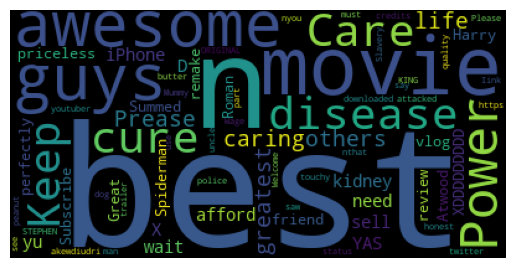

In [37]:
plt.imshow(wordcloud)
plt.axis('off')

In [38]:
### Conclusion-->> positive Users are emphasizing more on best , awesome , perfect , amazing , look , happy  etc..

In [39]:
total_comments_negative = ' '.join(comments_negative['comment_text'])

In [40]:
wordcloud2 = WordCloud(stopwords=set(STOPWORDS)).generate(total_comments_negative)

(np.float64(-0.5), np.float64(399.5), np.float64(199.5), np.float64(-0.5))

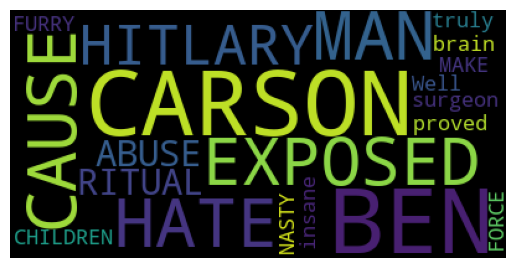

In [41]:
plt.imshow(wordcloud2)
plt.axis('off')

In [42]:
### Conclusion-->> Negative Users are emphasizing more on Terrible , worst ,horrible ,boring , disgusting etc..

## 4.. Perform Emoji's Analysis

In [43]:
!pip install emoji==2.2.0 ## 2.2.0 is a most stable version till date , hence installing this version makes sense !


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Invalid requirement: '##': Expected package name at the start of dependency specifier
    ##
    ^


In [44]:
import emoji

In [45]:
emoji.__version__

'2.15.0'

In [46]:
comments['comment_text'].head(6)

0                    Logan Paul it's yo big day ‼️‼️‼️
1    I've been following you from the start of your...
2                   Say hi to Kong and maverick for me
3                                  MY FAN . attendance
4                                           trending 😉
5                              #1 on trending AYYEEEEE
Name: comment_text, dtype: object

In [47]:
### lets extract emoji from below comment

In [48]:
comment = 'trending 😉'

In [49]:
[char for char in comment if char in emoji.EMOJI_DATA]

['😉']

In [50]:
## lets try to write above code in a more simpler & readable way :

In [51]:
emoji_list = []

for char in comment:
    if char in emoji.EMOJI_DATA:
        emoji_list.append(char)

In [52]:
emoji_list

['😉']

In [53]:
all_emojis_list = []

for comment in comments['comment_text'].dropna(): ## in case u have missing values , call dropna()
    for char in comment:
        if char in emoji.EMOJI_DATA:
            all_emojis_list.append(char)

In [54]:
all_emojis_list[0:10]

['‼', '‼', '‼', '😉', '😭', '👍', '🏻', '❤', '😍', '💋']

In [55]:
len(all_emojis_list)

272

In [56]:
### NOw we have to compute frequencies of each & every emoji in "all_emojis_list"..

In [57]:
from collections import Counter

In [58]:
emojis_count_list = Counter(all_emojis_list).most_common(20)

In [59]:
Counter(all_emojis_list).most_common(10)

[('😂', 105),
 ('💖', 14),
 ('👏', 10),
 ('😆', 9),
 ('😮', 9),
 ('👈', 8),
 ('😁', 8),
 ('❤', 7),
 ('😍', 7),
 ('🤣', 6)]

In [60]:
emojis_count_list

[('😂', 105),
 ('💖', 14),
 ('👏', 10),
 ('😆', 9),
 ('😮', 9),
 ('👈', 8),
 ('😁', 8),
 ('❤', 7),
 ('😍', 7),
 ('🤣', 6),
 ('😭', 5),
 ('💋', 5),
 ('😊', 5),
 ('👎', 5),
 ('👍', 4),
 ('🏻', 4),
 ('😴', 4),
 ('😃', 4),
 ('‼', 3),
 ('👌', 3)]

In [61]:
[emoji for emoji , count in emojis_count_list]

['😂',
 '💖',
 '👏',
 '😆',
 '😮',
 '👈',
 '😁',
 '❤',
 '😍',
 '🤣',
 '😭',
 '💋',
 '😊',
 '👎',
 '👍',
 '🏻',
 '😴',
 '😃',
 '‼',
 '👌']

In [62]:
[count for emoji , count in emojis_count_list]

[105, 14, 10, 9, 9, 8, 8, 7, 7, 6, 5, 5, 5, 5, 4, 4, 4, 4, 3, 3]

In [63]:
count = [count for emoji , count in emojis_count_list]

In [69]:
%pip install plotly

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [70]:
import plotly.express as px

In [71]:
px.bar(
    x=emojis,
    y=counts,
    title="Most used emojis in Youtube Comments",
    labels={
        "x": "Emoji",
        "y": "Count"
    }
)

NameError: name 'emojis' is not defined

In [74]:
Counter(all_emojis_list).most_common(10)[0]

('😂', 105)

In [75]:
Counter(all_emojis_list).most_common(10)[0][0]

'😂'

In [76]:
Counter(all_emojis_list).most_common(10)[1][0]

'💖'

In [77]:
Counter(all_emojis_list).most_common(10)[2][0]

'👏'

In [78]:
emojis = [Counter(all_emojis_list).most_common(10)[i][0] for i in range(10)]

In [79]:
Counter(all_emojis_list).most_common(10)[0][1]

105

In [80]:
Counter(all_emojis_list).most_common(10)[1][1]

14

In [81]:
Counter(all_emojis_list).most_common(10)[2][1]

10

In [82]:
freqs = [Counter(all_emojis_list).most_common(10)[i][1] for i in range(10)]

In [83]:
freqs

[105, 14, 10, 9, 9, 8, 8, 7, 7, 6]

In [84]:
%pip install plotly

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [85]:
import plotly.graph_objs as go
from plotly.offline import iplot

In [86]:
trace = go.Bar(x=emojis , y=freqs)

In [87]:

import sys 
!{sys.executable} -m pip install --upgrade nbformat ipython plotly

'c:\Users\jaishri' is not recognized as an internal or external command,
operable program or batch file.


In [88]:
## Conclusions : Majority of the customers are happy as most of them are using emojis like: funny , love , heart , outstanding..

## 5.. Collect Entire data of Youtube !

In [89]:
import os

In [93]:
files= os.listdir(r"C:\Data Analytics project\project- 1 youtube case-study\additional_data")

In [94]:
files

['CAvideos.csv',
 'CA_category_id.json',
 'DEvideos.csv',
 'DE_category_id.json',
 'FRvideos.csv',
 'FR_category_id.json',
 'GBvideos.csv',
 'GB_category_id.json',
 'INvideos.csv',
 'IN_category_id.json',
 'JPvideos.csv',
 'JP_category_id.json',
 'KRvideos.csv',
 'KR_category_id.json',
 'MXvideos.csv',
 'MX_category_id.json',
 'RUvideos.csv',
 'RU_category_id.json',
 'USvideos.csv',
 'US_category_id.json']

In [95]:
## extracting csv files only from above list ..

files_csv = [file for file in files if '.csv' in file]

In [96]:
files_csv

['CAvideos.csv',
 'DEvideos.csv',
 'FRvideos.csv',
 'GBvideos.csv',
 'INvideos.csv',
 'JPvideos.csv',
 'KRvideos.csv',
 'MXvideos.csv',
 'RUvideos.csv',
 'USvideos.csv']

In [97]:
import warnings
from warnings import filterwarnings
filterwarnings('ignore')

#### different types of encoding-->>
    Note : encoding may change depending upon data  , country data , sometimes regional data as well.
    Fore more inforation on Encoding -- Follow below
### https://docs.python.org/3/library/codecs.html#standard-encodings¶

In [100]:
full_df = pd.DataFrame()

path = r"C:\Data Analytics project\project- 1 youtube case-study\additional_data"
for file in files_csv:
    current_df = pd.read_csv(
        path + '/' + file,
        encoding='iso-8859-1',
        on_bad_lines='skip'
    )

    full_df = pd.concat([full_df, current_df], ignore_index=True)

In [101]:
full_df.shape

(375942, 16)

## 6.. How to export your data into (csv, json, db)

In [102]:
### upto some extent your data is cleaned , so lets export this data into various formats for further analysis :

In [103]:
'''

export your data into :
    a) csv 
    b) json
    c) db


'''

'\n\nexport your data into :\n    a) csv \n    b) json\n    c) db\n\n\n'

In [104]:
full_df[full_df.duplicated()].shape

(36417, 16)

In [105]:
'''
default value of keep='first'

It means that the method will consider the first instance of a row to be unique and the remaining instances to be duplicates.


keep='first' (default): mark all rows as duplicates except for the first occurrence.

keep='last': mark all rows as duplicates except for the last occurrence.

keep=False: mark all rows as all duplicates.


'''

"\ndefault value of keep='first'\n\nIt means that the method will consider the first instance of a row to be unique and the remaining instances to be duplicates.\n\n\nkeep='first' (default): mark all rows as duplicates except for the first occurrence.\n\nkeep='last': mark all rows as duplicates except for the last occurrence.\n\nkeep=False: mark all rows as all duplicates.\n\n\n"

In [106]:
full_df = full_df.drop_duplicates() ## lets drop duplicate rows ..

In [107]:
full_df.shape

(339525, 16)

#### a... Storing data into csv ..

In [109]:
### you can consider sample of data depending on how efficient your system is..

full_df[0:1000].to_csv(r"C:\Data Analytics project\project- 1 youtube case-study\UScomments.csv", index=False)

#### b... Storing data into json

In [113]:
full_df[0:1000].to_json(
    r"C:\Data Analytics project\project- 1 youtube case-study\export_data.json"
)

#### c... Storing data into database

In [114]:
#create engine allows us to connect to database
from sqlalchemy import create_engine

In [115]:
# Lets create sql_alchemy engine by using create_engine method ie create engine allows us to connect to database
engine = create_engine(r'sqlite:///Z:\1.. Youtube\export_data/youtube_sample.sqlite')

In [ ]:
from sqlalchemy import create_engine

engine = create_engine(
    r'sqlite:///D:/Data_Analytics_Project/Project - 1 Text_Data_Analytic ( Youtube Case-Study )/youtube.db'
)

In [122]:
full_df[0:1000].to_sql(
    'Users',
    con=engine,
    if_exists='replace',
    index=False
)

1000

In [123]:
## As soon as u have u have your data into 'youtube_sample.sqlite' which has table has 'Users', now u can read data from this db file 'youtube_whole_data.sqlite' using sqlite3 & pandas

## 7.. Which Category has the maximum likes ?

In [124]:
full_df.head(5)

,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description
0,n1WpP7iowLc,17.14.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,10,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787425,43420,125882,https://i.ytimg.com/vi/n1WpP7iowLc/default.jpg,False,False,False,Eminem's new track Walk on Water ft. BeyoncÃ© ...
1,0dBIkQ4Mz1M,17.14.11,PLUSH - Bad Unboxing Fan Mail,iDubbbzTV,23,2017-11-13T17:00:00.000Z,"plush|""bad unboxing""|""unboxing""|""fan mail""|""id...",1014651,127794,1688,13030,https://i.ytimg.com/vi/0dBIkQ4Mz1M/default.jpg,False,False,False,STill got a lot of packages. Probably will las...
2,5qpjK5DgCt4,17.14.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146035,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO â¶ \n\nSUBSCRIBE âº ...
3,d380meD0W0M,17.14.11,I Dare You: GOING BALD!?,nigahiga,24,2017-11-12T18:01:41.000Z,"ryan|""higa""|""higatv""|""nigahiga""|""i dare you""|""...",2095828,132239,1989,17518,https://i.ytimg.com/vi/d380meD0W0M/default.jpg,False,False,False,I know it's been a while since we did this sho...
4,2Vv-BfVoq4g,17.14.11,Ed Sheeran - Perfect (Official Music Video),Ed Sheeran,10,2017-11-09T11:04:14.000Z,"edsheeran|""ed sheeran""|""acoustic""|""live""|""cove...",33523622,1634130,21082,85067,https://i.ytimg.com/vi/2Vv-BfVoq4g/default.jpg,False,False,False,ð§: https://ad.gt/yt-perfect\nð°: https://...


In [125]:
full_df['category_id'].unique()

array([10, 23, 24, 25, 22, 26,  1, 28, 20, 17, 29, 15, 19,  2, 27, 43, 30,
       44])

In [127]:
json_df = pd.read_json(
    r"C:\Data Analytics project\project- 1 youtube case-study\additional_data\US_category_id.json"
)

In [128]:
json_df

,kind,etag,items
0,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
1,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
2,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
3,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
4,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
5,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
6,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
7,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
8,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
9,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."


In [129]:
json_df['items'][0]

### each row of 'Items' feature is dictionary .. 

{'kind': 'youtube#videoCategory',
 'etag': '"m2yskBQFythfE4irbTIeOgYYfBU/Xy1mB4_yLrHy_BmKmPBggty2mZQ"',
 'id': '1',
 'snippet': {'channelId': 'UCBR8-60-B28hp2BmDPdntcQ',
  'title': 'Film & Animation',
  'assignable': True}}

In [130]:
json_df['items'][1]

{'kind': 'youtube#videoCategory',
 'etag': '"m2yskBQFythfE4irbTIeOgYYfBU/UZ1oLIIz2dxIhO45ZTFR3a3NyTA"',
 'id': '2',
 'snippet': {'channelId': 'UCBR8-60-B28hp2BmDPdntcQ',
  'title': 'Autos & Vehicles',
  'assignable': True}}

In [131]:
cat_dict = {}

for item in json_df['items'].values:
    ## cat_dict[key] = value (Syntax to insert key:value in dictionary)
    cat_dict[int(item['id'])] = item['snippet']['title']

In [132]:
cat_dict

{1: 'Film & Animation',
 2: 'Autos & Vehicles',
 10: 'Music',
 15: 'Pets & Animals',
 17: 'Sports',
 18: 'Short Movies',
 19: 'Travel & Events',
 20: 'Gaming',
 21: 'Videoblogging',
 22: 'People & Blogs',
 23: 'Comedy',
 24: 'Entertainment',
 25: 'News & Politics',
 26: 'Howto & Style',
 27: 'Education',
 28: 'Science & Technology',
 29: 'Nonprofits & Activism',
 30: 'Movies',
 31: 'Anime/Animation',
 32: 'Action/Adventure',
 33: 'Classics',
 34: 'Comedy',
 35: 'Documentary',
 36: 'Drama',
 37: 'Family',
 38: 'Foreign',
 39: 'Horror',
 40: 'Sci-Fi/Fantasy',
 41: 'Thriller',
 42: 'Shorts',
 43: 'Shows',
 44: 'Trailers'}

In [133]:
full_df['category_name'] = full_df['category_id'].map(cat_dict)

In [134]:
full_df.head(4)

,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,category_name
0,n1WpP7iowLc,17.14.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,10,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787425,43420,125882,https://i.ytimg.com/vi/n1WpP7iowLc/default.jpg,False,False,False,Eminem's new track Walk on Water ft. BeyoncÃ© ...,Music
1,0dBIkQ4Mz1M,17.14.11,PLUSH - Bad Unboxing Fan Mail,iDubbbzTV,23,2017-11-13T17:00:00.000Z,"plush|""bad unboxing""|""unboxing""|""fan mail""|""id...",1014651,127794,1688,13030,https://i.ytimg.com/vi/0dBIkQ4Mz1M/default.jpg,False,False,False,STill got a lot of packages. Probably will las...,Comedy
2,5qpjK5DgCt4,17.14.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146035,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO â¶ \n\nSUBSCRIBE âº ...,Comedy
3,d380meD0W0M,17.14.11,I Dare You: GOING BALD!?,nigahiga,24,2017-11-12T18:01:41.000Z,"ryan|""higa""|""higatv""|""nigahiga""|""i dare you""|""...",2095828,132239,1989,17518,https://i.ytimg.com/vi/d380meD0W0M/default.jpg,False,False,False,I know it's been a while since we did this sho...,Entertainment


In [135]:
import matplotlib.pyplot as plt
import seaborn as sns

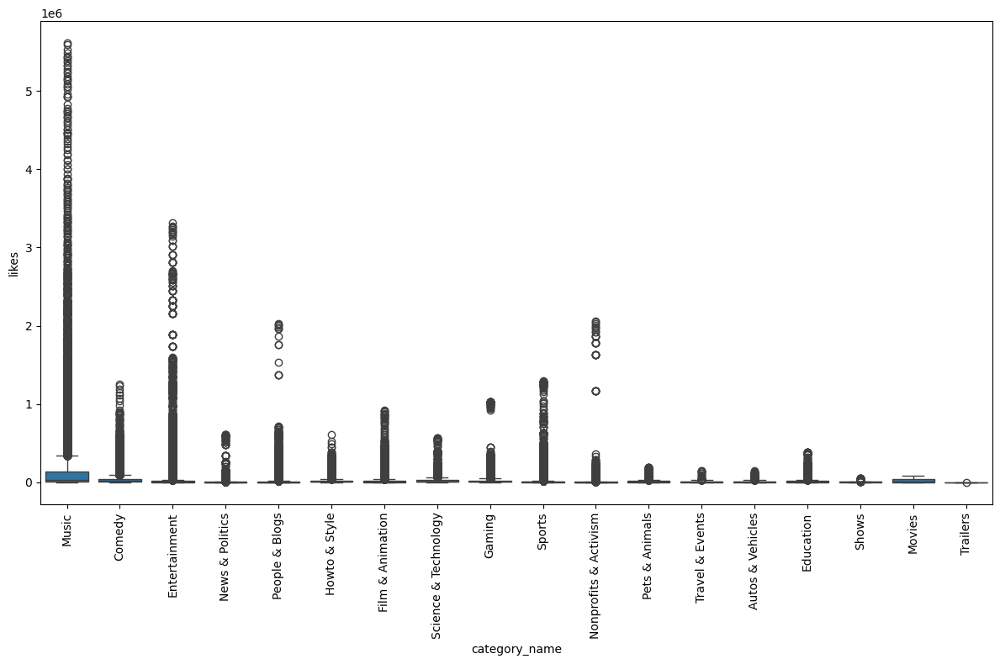

In [136]:
plt.figure(figsize=(12,8))

sns.boxplot(
    x='category_name',
    y='likes',
    data=full_df
)

plt.xticks(rotation='vertical')
plt.tight_layout()
plt.show()

Do Viral videos Actually Get Engegement ?

In [138]:
full_df.columns

Index(['video_id', 'trending_date', 'title', 'channel_title', 'category_id',
       'publish_time', 'tags', 'views', 'likes', 'dislikes', 'comment_count',
       'thumbnail_link', 'comments_disabled', 'ratings_disabled',
       'video_error_or_removed', 'description', 'category_name'],
      dtype='object')

In [147]:
full_df["engagement_rate"] = (full_df["likes"] + full_df["comment_count"]) / full_df["views"]

In [142]:

bubble_sample = full_df.sample(50000)


In [149]:
bubble = px.scatter(bubble_sample ,
                    x = "views",
                    y = "engagement_rate",
                    size = "comment_count",
                    color = "category_name",
                    hover_name = "title",
                    title = "Engagement Bubble Map : Views vs Engagement rate",
                    size_max= 60)

In [150]:
bubble.update_xaxes(type="log")

## 8.. Find out whether audience is engaged or not

In [151]:
full_df['like_rate'] = (full_df['likes']/full_df['views'])*100
full_df['dislike_rate'] = (full_df['dislikes']/full_df['views'])*100
full_df['comment_count_rate'] = (full_df['comment_count']/full_df['views'])*100

In [152]:
full_df.columns

Index(['video_id', 'trending_date', 'title', 'channel_title', 'category_id',
       'publish_time', 'tags', 'views', 'likes', 'dislikes', 'comment_count',
       'thumbnail_link', 'comments_disabled', 'ratings_disabled',
       'video_error_or_removed', 'description', 'category_name',
       'Engagement_rate', 'engagement_rate', 'like_rate', 'dislike_rate',
       'comment_count_rate'],
      dtype='object')

In [155]:
category_metrics = full_df.groupby('category_name').agg(
    total_views = ("views", "sum"),
    avg_engagement_efficiency = ("engagement_rate", "mean"),
    video_count = ("video_id", "count")).reset_index()


In [156]:
category_metrics

,category_name,total_views,avg_engagement_efficiency,video_count
0,Autos & Vehicles,1514202384,0.049873,4596
1,Comedy,18341009925,0.058413,24024
2,Education,2485052061,0.057669,7396
3,Entertainment,85162066718,0.036217,97365
4,Film & Animation,20397383805,0.033448,18329
5,Gaming,6216418800,0.057708,10433
6,Howto & Style,8271658225,0.062121,17549
7,Movies,33047793,0.016044,22
8,Music,220389615568,0.051929,36990
9,News & Politics,8817653917,0.028820,34599


In [157]:
category_metrics.columns

Index(['category_name', 'total_views', 'avg_engagement_efficiency',
       'video_count'],
      dtype='object')

In [ ]:
treemap = px.treemap(
    category_metrics,
    path = ["category_name"],
    values = "total_views",
    color = "avg_engagement_efficiency",
    color_continuous_scale = "RdYlGn",
    title = "Category Attention Share with Engagement Efficiency Overlay",
    hover_data= {
        "total_views" : ":,.0f",
        "avg_engagement_efficiency" : ":.3f",
        "video_count" : True
    }
)



In [161]:
treemap 

Is the audience actually engaged ?

In [162]:
full_df.columns

Index(['video_id', 'trending_date', 'title', 'channel_title', 'category_id',
       'publish_time', 'tags', 'views', 'likes', 'dislikes', 'comment_count',
       'thumbnail_link', 'comments_disabled', 'ratings_disabled',
       'video_error_or_removed', 'description', 'category_name',
       'Engagement_rate', 'engagement_rate', 'like_rate', 'dislike_rate',
       'comment_count_rate'],
      dtype='object')

In [163]:
full_df["engagement_rate"].describe()

count    339525.000000
mean          0.042103
std           0.043971
min           0.000000
25%           0.010395
50%           0.027453
75%           0.060261
max           0.957256
Name: engagement_rate, dtype: float64

In [167]:
category_engagement_stats = full_df.groupby('category_name')['engagement_rate'].describe()

In [170]:
category_engagement_stats.sort_values("mean" , ascending= False)

,count,mean,std,min,25%,50%,75%,max
category_name,,,,,,,,
Howto & Style,17549.0,0.062121,0.042688,0.000000,0.032948,0.052991,0.082680,0.709778
Science & Technology,7350.0,0.058860,0.053710,0.000000,0.024923,0.047330,0.077522,0.774282
Comedy,24024.0,0.058413,0.046692,0.000000,0.022036,0.048903,0.082108,0.746056
Gaming,10433.0,0.057708,0.048587,0.000000,0.022935,0.048472,0.078039,0.863608
Education,7396.0,0.057669,0.042375,0.000000,0.028697,0.050298,0.077079,0.445312
Music,36990.0,0.051929,0.045435,0.000000,0.021012,0.038634,0.067957,0.506464
Pets & Animals,4215.0,0.050707,0.039806,0.000000,0.023875,0.040444,0.066759,0.330806
Autos & Vehicles,4596.0,0.049873,0.035542,0.000000,0.024870,0.045179,0.068422,0.234820
Nonprofits & Activism,2722.0,0.049619,0.058793,0.000000,0.009192,0.023070,0.074042,0.704366


In [171]:
full_df.columns

Index(['video_id', 'trending_date', 'title', 'channel_title', 'category_id',
       'publish_time', 'tags', 'views', 'likes', 'dislikes', 'comment_count',
       'thumbnail_link', 'comments_disabled', 'ratings_disabled',
       'video_error_or_removed', 'description', 'category_name',
       'Engagement_rate', 'engagement_rate', 'like_rate', 'dislike_rate',
       'comment_count_rate'],
      dtype='object')

In [172]:
box = px.box(full_df,
             x = "category_name",
             y = "engagement_rate",
             color = "category_name",
             title = "Audience Engagement by Category")



In [173]:
box

## 9.. Which channels have the largest number of trending videos?

In [ ]:
full_df.head(6)

,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,category_name,like_rate,dislike_rate,comment_count_rate
0,n1WpP7iowLc,17.14.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,10,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787425,43420,125882,https://i.ytimg.com/vi/n1WpP7iowLc/default.jpg,False,False,False,Eminem's new track Walk on Water ft. BeyoncÃ© ...,Music,4.589104,0.253051,0.733639
1,0dBIkQ4Mz1M,17.14.11,PLUSH - Bad Unboxing Fan Mail,iDubbbzTV,23,2017-11-13T17:00:00.000Z,"plush|""bad unboxing""|""unboxing""|""fan mail""|""id...",1014651,127794,1688,13030,https://i.ytimg.com/vi/0dBIkQ4Mz1M/default.jpg,False,False,False,STill got a lot of packages. Probably will las...,Comedy,12.594873,0.166363,1.284185
2,5qpjK5DgCt4,17.14.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146035,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO â¶ \n\nSUBSCRIBE âº ...,Comedy,4.575843,0.167292,0.256342
3,d380meD0W0M,17.14.11,I Dare You: GOING BALD!?,nigahiga,24,2017-11-12T18:01:41.000Z,"ryan|""higa""|""higatv""|""nigahiga""|""i dare you""|""...",2095828,132239,1989,17518,https://i.ytimg.com/vi/d380meD0W0M/default.jpg,False,False,False,I know it's been a while since we did this sho...,Entertainment,6.309630,0.094903,0.835851
4,2Vv-BfVoq4g,17.14.11,Ed Sheeran - Perfect (Official Music Video),Ed Sheeran,10,2017-11-09T11:04:14.000Z,"edsheeran|""ed sheeran""|""acoustic""|""live""|""cove...",33523622,1634130,21082,85067,https://i.ytimg.com/vi/2Vv-BfVoq4g/default.jpg,False,False,False,ð§: https://ad.gt/yt-perfect\nð°: https://...,Music,4.874563,0.062887,0.253752
5,0yIWz1XEeyc,17.14.11,Jake Paul Says Alissa Violet CHEATED with LOGA...,DramaAlert,25,2017-11-13T07:37:51.000Z,"#DramaAlert|""Drama""|""Alert""|""DramaAlert""|""keem...",1309699,103755,4613,12143,https://i.ytimg.com/vi/0yIWz1XEeyc/default.jpg,False,False,False,âº Follow for News! - https://twitter.com/KEE...,News & Politics,7.922049,0.352218,0.927160


In [ ]:
full_df['channel_title'].value_counts()

channel_title
The Late Show with Stephen Colbert    710
WWE                                   643
Late Night with Seth Meyers           592
TheEllenShow                          555
Jimmy Kimmel Live                     528
                                     ... 
The Secrets of Dairy                    1
babygranderecords                       1
24 Oras News Today                      1
turk2doubleoh8                          1
BOOMPANOT.COM                           1
Name: count, Length: 37824, dtype: int64

In [ ]:
### lets obtain above frequency table using groupby approach : 

In [ ]:
cdf = full_df.groupby(['channel_title']).size().sort_values(ascending=False).reset_index()

In [ ]:
cdf = cdf.rename(columns={0:'total_videos'})

In [ ]:
cdf

,channel_title,total_videos
0,The Late Show with Stephen Colbert,710
1,WWE,643
2,Late Night with Seth Meyers,592
3,TheEllenShow,555
4,Jimmy Kimmel Live,528
...,...,...
37819,Tesoros Enterrados,1
37820,Anton Neverov,1
37821,Thalia 444,1
37822,Thaitv6 Official,1


In [ ]:
import plotly.express as px

In [ ]:
px.bar(data_frame=cdf[0:20] , x='channel_title' , y='total_videos')

## 10.. Does Punctuations in title and tags have any relation with views, likes, dislikes comments?

In [ ]:
full_df['title'][0]

'Eminem - Walk On Water (Audio) ft. BeyoncÃ©'

In [ ]:
import string

In [ ]:
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [ ]:
len([char for char in full_df['title'][0] if char in string.punctuation])

4

In [ ]:
def punc_count(text):
    return len([char for char in text if char in string.punctuation])

In [ ]:
sample = full_df[0:10000]

In [ ]:
sample['count_punc'] = sample['title'].apply(punc_count)

In [ ]:
sample['count_punc']

0       4
1       1
2       3
3       3
4       3
       ..
9995    6
9996    0
9997    1
9998    0
9999    6
Name: count_punc, Length: 10000, dtype: int64

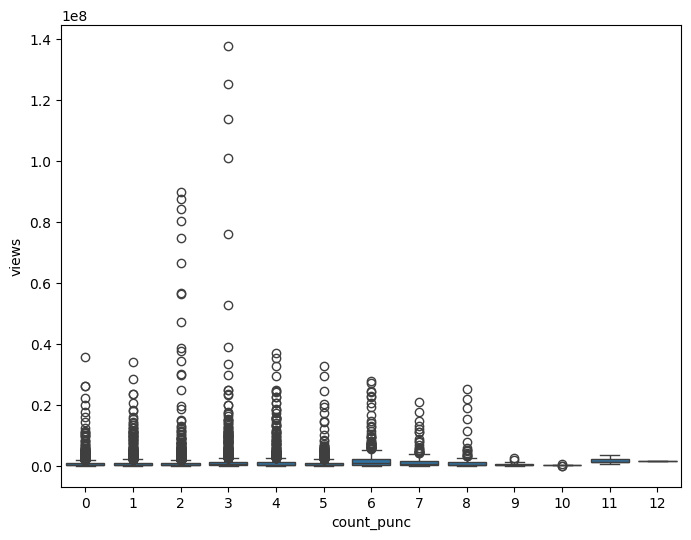

In [ ]:
plt.figure(figsize=(8,6))
sns.boxplot(x='count_punc' , y='views' , data=sample)
plt.show()

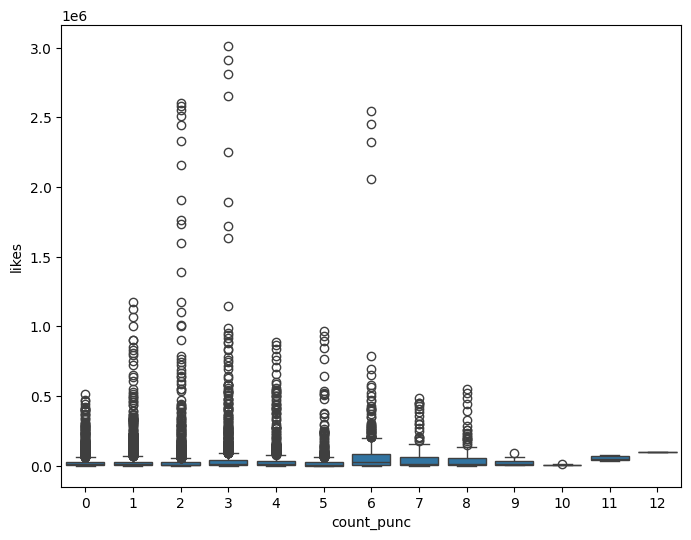

In [ ]:
plt.figure(figsize=(8,6))
sns.boxplot(x='count_punc' , y='likes' , data=sample)
plt.show()